<a href="https://colab.research.google.com/github/Ishany0/audio_cats_dogs_mlp/blob/main/audio_cats_dogs_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
## Cats vs Dogs audio classification
## feature extraction using librosa + MLP (perceptron) for results
## steps : load data -> clean + normalize -> extract features -> MLP -> compare raw vs cleaned

In [2]:
!pip install noisereduce

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mmoreaux/audio-cats-and-dogs")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'audio-cats-and-dogs' dataset.
Path to dataset files: /kaggle/input/audio-cats-and-dogs


In [4]:
import time
import hashlib
import numpy as np
import pandas as pd
import librosa
import librosa.display
import noisereduce as nr
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [5]:
## getting all the wav files and labels (cat or dog) from the file name / folder name
## NOTE : folder "cats_dogs" has BOTH words, so it must not be used for labelling
## -> check the file name first, use the folder name only if it has just one of the two words

all_files = []
all_labels = []

def get_label(p):
    for key in (p.name.lower() , p.parent.name.lower()):
        if "cat" in key and "dog" not in key:
            return "cat"
        if "dog" in key and "cat" not in key:
            return "dog"
    return None

for p in Path(path).rglob("*.wav"):
    l = get_label(p)
    if l is not None:
        all_files.append(str(p))
        all_labels.append(l)

print("total files :", len(all_files))
print(Counter(all_labels))

## both cat and dog should be there, else the labelling is wrong
assert len(set(all_labels)) == 2 , "only one class found, check labels"

total files : 554
Counter({'cat': 328, 'dog': 226})


In [6]:
## same file can be present twice (train and test folder) -> remove it, else test data leaks into train

seen = set()
files = []
labels = []

for f , l in zip(all_files , all_labels):
    h = hashlib.md5(open(f , "rb").read()).hexdigest()
    if h not in seen:
        seen.add(h)
        files.append(f)
        labels.append(l)

print("after removing duplicates :", len(files))
print(Counter(labels))

after removing duplicates : 276
Counter({'cat': 164, 'dog': 112})


In [7]:
## sample rate check (same as before)

rates = Counter()
for p in files:
    info = sf.info(p)
    rates[(info.samplerate, info.channels)] += 1

print(rates)

#only one key : means same frequency all across (16000) -> no need to resample

Counter({(16000, 1): 276})


min : 0.9233125  mean : 6.947263360507246  max : 17.976


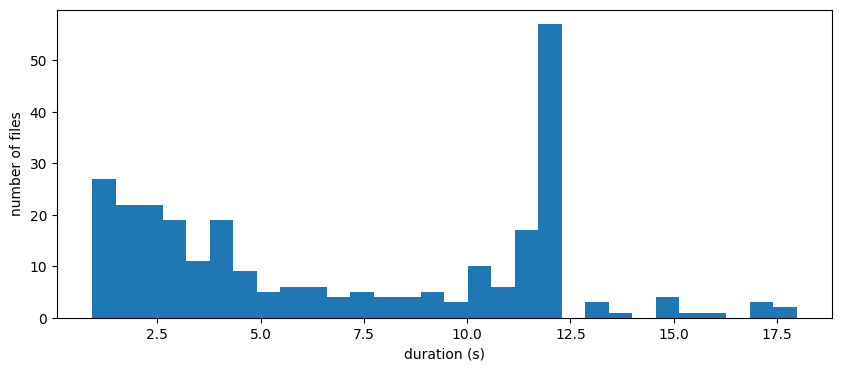

In [8]:
## duration of audios (variable length)

durations = [sf.info(p).duration for p in files]
print("min :", np.min(durations) , " mean :", np.mean(durations) , " max :", np.max(durations))

plt.figure(figsize = (10,4))
plt.hist(durations , bins = 30)
plt.xlabel("duration (s)")
plt.ylabel("number of files")
plt.show()

## length is different for every file, so we take mean and std of the features over time
## -> every audio gives a feature vector of same size, no padding needed

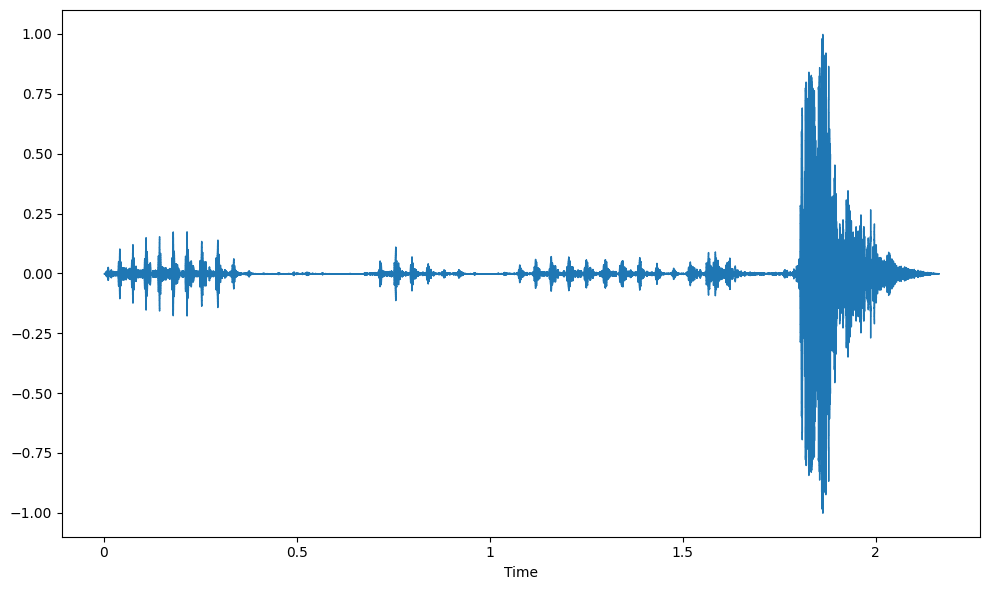

In [9]:
## data cleaning + normalization on one file (just to see)

random_path = files[0]
y , sr = librosa.load(random_path , sr = None)

cleaned_audio = nr.reduce_noise(y = y , sr = sr)
y_normalized = librosa.util.normalize(cleaned_audio)

plt.figure(figsize = (10,6))
librosa.display.waveshow(y_normalized , sr = sr)
plt.tight_layout()
plt.show()

In [10]:
## feature extraction function
## clean = True  -> noise reduction is applied
## clean = False -> only normalization

def extract_features(file_path , clean = False):
    y , sr = librosa.load(file_path , sr = None)

    if clean:
        y = nr.reduce_noise(y = y , sr = sr)
    y = librosa.util.normalize(y)

    # MFCC (40)
    mfcc = librosa.feature.mfcc(y = y , sr = sr , n_mfcc = 40)
    mfcc_mean = np.mean(mfcc , axis = 1)
    mfcc_std = np.std(mfcc , axis = 1)

    # mel spectrogram (in dB)
    mel = librosa.feature.melspectrogram(y = y , sr = sr , n_mels = 32 , fmax = 8000)
    mel_db = librosa.power_to_db(mel , ref = np.max)
    mel_mean = np.mean(mel_db , axis = 1)

    # other spectral features
    centroid = np.mean(librosa.feature.spectral_centroid(y = y , sr = sr))
    bandwidth = np.mean(librosa.feature.spectral_bandwidth(y = y , sr = sr))
    rolloff = np.mean(librosa.feature.spectral_rolloff(y = y , sr = sr))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rms = np.mean(librosa.feature.rms(y = y))

    # pitch (piptrack)
    pitches , magnitudes = librosa.piptrack(y = y , sr = sr)
    pitch_values = []
    for i in range(pitches.shape[1]):
        index = magnitudes[: , i].argmax()
        pitch = pitches[index , i]
        if pitch > 0:
            pitch_values.append(pitch)
    if len(pitch_values) > 0:
        pitch_mean = np.mean(pitch_values)
    else:
        pitch_mean = 0

    features = np.concatenate([mfcc_mean , mfcc_std , mel_mean , [centroid , bandwidth , rolloff , zcr , rms , pitch_mean]])
    return features

# checking on one file
f = extract_features(files[0])
print(f.shape)

(118,)


In [11]:
## features for all files WITHOUT noise reduction

start = time.time()
X_raw = []
for p in files:
    X_raw.append(extract_features(p , clean = False))
X_raw = np.nan_to_num(np.array(X_raw))
time_raw = time.time() - start

print(X_raw.shape)
print("time taken (raw) :", round(time_raw , 1) , "sec")

(276, 118)
time taken (raw) : 36.0 sec


In [12]:
## features for all files WITH noise reduction

start = time.time()
X_clean = []
for p in files:
    X_clean.append(extract_features(p , clean = True))
X_clean = np.nan_to_num(np.array(X_clean))
time_clean = time.time() - start

print(X_clean.shape)
print("time taken (cleaned) :", round(time_clean , 1) , "sec")

## this answers the time question : noise reduction makes feature extraction slower

(276, 118)
time taken (cleaned) : 50.3 sec


In [13]:
## labels : cat = 0 , dog = 1

y = np.array([0 if l == "cat" else 1 for l in labels])
print(Counter(y))

Counter({np.int64(0): 164, np.int64(1): 112})


accuracy (raw) : 0.7857142857142857
              precision    recall  f1-score   support

         cat       0.74      0.97      0.84        33
         dog       0.92      0.52      0.67        23

    accuracy                           0.79        56
   macro avg       0.83      0.75      0.75        56
weighted avg       0.82      0.79      0.77        56



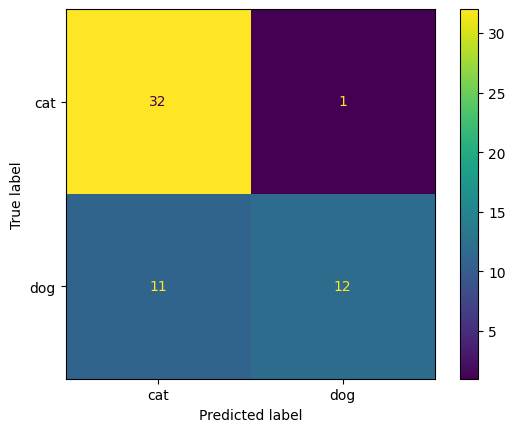

In [14]:
## MLP on raw data

X_train , X_test , y_train , y_test = train_test_split(X_raw , y , test_size = 0.2 , random_state = 42 , stratify = y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

mlp = MLPClassifier(hidden_layer_sizes = (128 , 64) , activation = "relu" , alpha = 0.001 , max_iter = 500 , early_stopping = True , random_state = 42)
mlp.fit(X_train_s , y_train)

y_pred = mlp.predict(X_test_s)
acc_raw = accuracy_score(y_test , y_pred)

print("accuracy (raw) :" , acc_raw)
print(classification_report(y_test , y_pred , target_names = ["cat" , "dog"]))

ConfusionMatrixDisplay(confusion_matrix(y_test , y_pred) , display_labels = ["cat" , "dog"]).plot()
plt.show()

accuracy (cleaned) : 0.7857142857142857
              precision    recall  f1-score   support

         cat       0.73      1.00      0.85        33
         dog       1.00      0.48      0.65        23

    accuracy                           0.79        56
   macro avg       0.87      0.74      0.75        56
weighted avg       0.84      0.79      0.76        56



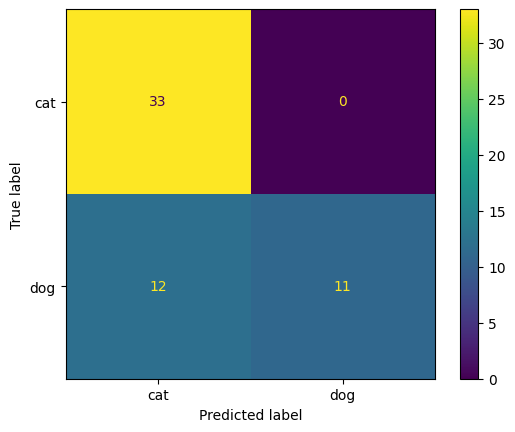

In [15]:
## MLP on cleaned data (same split, same settings)

X_train , X_test , y_train , y_test = train_test_split(X_clean , y , test_size = 0.2 , random_state = 42 , stratify = y)

scaler_c = StandardScaler()
X_train_s = scaler_c.fit_transform(X_train)
X_test_s = scaler_c.transform(X_test)

mlp_c = MLPClassifier(hidden_layer_sizes = (128 , 64) , activation = "relu" , alpha = 0.001 , max_iter = 500 , early_stopping = True , random_state = 42)
mlp_c.fit(X_train_s , y_train)

y_pred = mlp_c.predict(X_test_s)
acc_clean = accuracy_score(y_test , y_pred)

print("accuracy (cleaned) :" , acc_clean)
print(classification_report(y_test , y_pred , target_names = ["cat" , "dog"]))

ConfusionMatrixDisplay(confusion_matrix(y_test , y_pred) , display_labels = ["cat" , "dog"]).plot()
plt.show()

In [16]:
## single split can be lucky -> 5 fold cross validation for both

from sklearn.pipeline import make_pipeline

model = make_pipeline(StandardScaler() , MLPClassifier(hidden_layer_sizes = (128 , 64) , alpha = 0.001 , max_iter = 500 , early_stopping = True , random_state = 42))

cv_raw = cross_val_score(model , X_raw , y , cv = 5)
cv_clean = cross_val_score(model , X_clean , y , cv = 5)

print("raw     :" , cv_raw.mean() , "+/-" , cv_raw.std())
print("cleaned :" , cv_clean.mean() , "+/-" , cv_clean.std())

raw     : 0.8914285714285715 +/- 0.024989118900375473
cleaned : 0.8986363636363635 +/- 0.033389759404012655


In [17]:
## final comparison : does cleaning make any difference in prediction ??

result = pd.DataFrame({
    "extraction time (s)" : [time_raw , time_clean],
    "test accuracy" : [acc_raw , acc_clean],
    "cv accuracy" : [cv_raw.mean() , cv_clean.mean()],
    "cv std" : [cv_raw.std() , cv_clean.std()]
} , index = ["raw" , "cleaned"])

print(result.round(3))

## if the cv accuracy difference is smaller than the std -> no real difference, so noise reduction is not worth the extra time

         extraction time (s)  test accuracy  cv accuracy  cv std
raw                   36.050          0.786        0.891   0.025
cleaned               50.307          0.786        0.899   0.033


In [18]:
## prediction on a single audio file

def predict_audio(file_path , model , scaler , clean = False):
    f = extract_features(file_path , clean = clean)
    f = np.nan_to_num(f).reshape(1 , -1)
    f = scaler.transform(f)
    pred = model.predict(f)[0]
    return "cat" if pred == 0 else "dog"

print(files[0] , "->" , predict_audio(files[0] , mlp , scaler))

/kaggle/input/audio-cats-and-dogs/cats_dogs/dog_barking_102.wav -> cat
